<a href="https://colab.research.google.com/github/Mkhalifa8996/Data-Science/blob/main/Transfer_Learning_fine_tuning/Transfer_Learning_fine_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transfer Learning using Fine-tuning



In [124]:
import tensorflow as tf
import numpy as np
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import pathlib
import os, random
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers
from tensorflow.keras import models
from tensorflow import keras


In [125]:
# Check if we are using GPU
!nvidia-smi

Tue Oct 13 15:32:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   73C    P0             28W /   70W |    1153MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [126]:
# Generating image datagenerators
IMG_SIZE=(224,224)
BATCH_SIZE=32
INPUT_SHAPE= IMG_SIZE + (3,) # (224,224,3)
EPOCHS=5

# Creating helper functions
**It's a file of commonly used functions, that is saved to my gethub, It can be found here: https://raw.githubusercontent.com/Mkhalifa8996/Data-Science/refs/heads/main/extras/helper_functions.py**

In [127]:
!wget https://raw.githubusercontent.com/Mkhalifa8996/Data-Science/refs/heads/main/extras/helper_functions.py

--2026-10-13 15:32:29--  https://raw.githubusercontent.com/Mkhalifa8996/Data-Science/refs/heads/main/extras/helper_functions.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10246 (10K) [text/plain]
Saving to: ‘helper_functions.py.2’

helper_functions.py 100%[===================>]  10.01K  --.-KB/s    in 0s      

2026-10-13 15:32:29 (86.3 MB/s) - ‘helper_functions.py.2’ saved [10246/10246]



# Import functions from the helper_functions file

In [128]:
from helper_functions import create_tensorboard_callback, plot_loss_curves, walk_through_dir, unzip_data

**Using pretrained models within tf.keras.application, and apply them to our problem.**
Link: https://www.tensorflow.org/api_docs/python/tf/keras/applications

In [129]:
# Get training data, 10% of training data with 10 classes
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_10_percent.zip

--2026-10-13 15:32:29--  https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_10_percent.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.137.207, 142.251.2.207, 142.250.141.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.137.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 168546183 (161M) [application/zip]
Saving to: ‘10_food_classes_10_percent.zip.2’

10_food_classes_10_ 100%[===================>] 160.74M   227MB/s    in 0.7s    

2026-10-13 15:32:30 (227 MB/s) - ‘10_food_classes_10_percent.zip.2’ saved [168546183/168546183]



In [130]:
# Unzip the dataset
unzip_data("/content/10_food_classes_10_percent.zip")

In [131]:
# Pass through dataset
walk_through_dir("/content/10_food_classes_10_percent")

There are 2 directories and 0 images in '/content/10_food_classes_10_percent'.
There are 10 directories and 0 images in '/content/10_food_classes_10_percent/train'.
There are 0 directories and 75 images in '/content/10_food_classes_10_percent/train/sushi'.
There are 0 directories and 75 images in '/content/10_food_classes_10_percent/train/steak'.
There are 0 directories and 75 images in '/content/10_food_classes_10_percent/train/pizza'.
There are 0 directories and 75 images in '/content/10_food_classes_10_percent/train/hamburger'.
There are 0 directories and 75 images in '/content/10_food_classes_10_percent/train/chicken_curry'.
There are 0 directories and 75 images in '/content/10_food_classes_10_percent/train/ice_cream'.
There are 0 directories and 75 images in '/content/10_food_classes_10_percent/train/ramen'.
There are 0 directories and 75 images in '/content/10_food_classes_10_percent/train/grilled_salmon'.
There are 0 directories and 75 images in '/content/10_food_classes_10_perc

In [132]:
# Creating training and test directory paths
train_dir = "/content/10_food_classes_10_percent/train"
test_dir = "/content/10_food_classes_10_percent/test"

# Generate a tf.data.Dataset from image files in a directory.
we use this image genrator instead of ImageDataGenerator because:
1.   It is faster
2.   It converts our images ito batches of tensors.




In [133]:
# Generating image datagenerators
print("Training data: ")
train_data = image_dataset_from_directory(
    directory=train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

print("Test data: ")
test_data = image_dataset_from_directory(
    directory=test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)



Training data: 
Found 750 files belonging to 10 classes.
Test data: 
Found 2500 files belonging to 10 classes.


In [134]:
train_data

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10), dtype=tf.float32, name=None))>

In [135]:
# Get the class names of training dataset
train_data.class_names

['chicken_curry',
 'chicken_wings',
 'fried_rice',
 'grilled_salmon',
 'hamburger',
 'ice_cream',
 'pizza',
 'ramen',
 'steak',
 'sushi']

In [136]:
# Get one batch of the training dataset
for images, labels in train_data.take(1):
  print(images, labels)

tf.Tensor(
[[[[ 55.65848     7.658482    3.658482 ]
   [ 57.587055    8.658483    4.0470343]
   [ 67.301346    8.658483    6.872768 ]
   ...
   [ 61.517395    6.482607    5.       ]
   [ 59.127037    6.317119    4.7056804]
   [ 53.70893     6.7804646   4.423287 ]]

  [[ 54.950893    7.0245533   3.7458544]
   [ 56.857143    7.9285717   3.9285717]
   [ 65.64286     7.          5.214286 ]
   ...
   [ 57.970184    7.005261    5.581994 ]
   [ 55.900497    6.092487    5.186728 ]
   [ 51.18743     6.015784    5.6358085]]

  [[ 53.          8.          5.       ]
   [ 56.149555    8.029655    4.0801973]
   [ 65.0869      7.707589    6.629464 ]
   ...
   [ 54.10699     7.062653    6.707589 ]
   [ 52.61236     6.2715206   7.6361475]
   [ 46.1232      6.4407034   5.8120317]]

  ...

  [[  6.          6.          6.       ]
   [  6.          6.          6.       ]
   [  6.          6.          6.       ]
   ...
   [ 28.093874   27.981932   25.584839 ]
   [ 29.578936   28.698812   25.334202 ]
   [ 

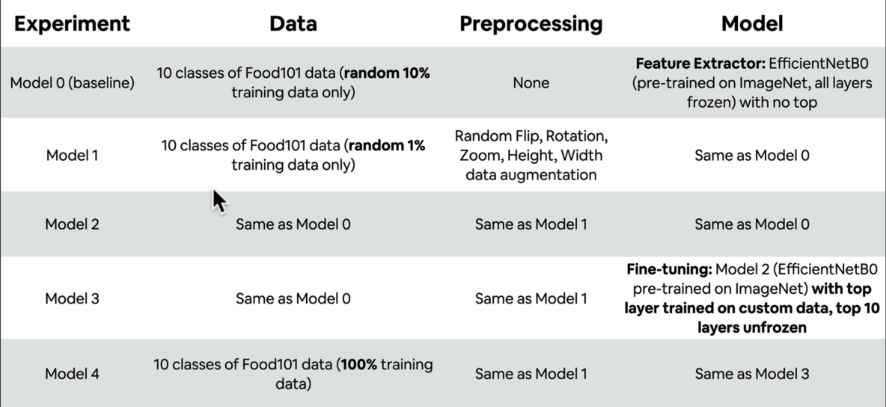

# Experiment 0 (baseline)
**Model 0: Building a transfer learning model using Functional API rather than Sequential API.**

Using Feature Extractor with 10% of the training data, no augmentation

In [137]:
# Create the base model
base_model = tf.keras.applications.EfficientNetB0(include_top=False)

# 2. Freeze the base model (so the pretrained patterns or weights are not updated)
base_model.trainable= False

# 3. Create the inputs into our model
inputs = tf.keras.Input(shape=INPUT_SHAPE, name="Input_layer")
print(f"Shape of inputs: {inputs.shape}")

# Some models such as ResNet50V0 may need input normalization
# x = tf.keras.layers.Rescaling(1/255.0)

# 4. Pass the inputs to the base model
x = base_model(inputs)
print(f"Shape after passing inputs through the base model: {x.shape}")

# 5. Average pool the output of the base model
x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
print(f"Shape after GlobalAveragePooling2D: {x.shape}")

# 6. Create the output activation layer
outputs =tf.keras.layers.Dense(10, activation="softmax", name="output_layer")(x)

# 7. Combine the input with the output
model_0 = tf.keras.Model(inputs, outputs)

# 8. Compile the model
model_0.compile(
    loss="categorical_crossentropy",
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"]
)


Shape of inputs: (None, 224, 224, 3)
Shape after passing inputs through the base model: (None, 7, 7, 1280)
Shape after GlobalAveragePooling2D: (None, 1280)


In [138]:
history_0 = model_0.fit(
    train_data,
    epochs= EPOCHS,
    steps_per_epoch=len(train_data),
    validation_data=test_data,
    validation_steps=int(0.25 * len(test_data)), # use 25% of test data
    callbacks=[create_tensorboard_callback(
        dir_name="transfer_learningn",
        experiment_name="model_0"
    )],
    verbose=1,

)

Saving TensorBoard log files to: transfer_learningn/model_0/20261013-153239
Epoch 1/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 39s 782ms/step - accuracy: 0.4213 - loss: 1.9024 - val_accuracy: 0.7648 - val_loss: 1.2976
Epoch 2/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 291ms/step - accuracy: 0.7653 - loss: 1.1013 - val_accuracy: 0.8421 - val_loss: 0.8485
Epoch 3/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 188ms/step - accuracy: 0.8320 - loss: 0.7838 - val_accuracy: 0.8569 - val_loss: 0.6673
Epoch 4/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 0.8653 - loss: 0.6326 - val_accuracy: 0.8503 - val_loss: 0.5937
Epoch 5/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - accuracy: 0.8733 - loss: 0.5466 - val_accuracy: 0.8487 - val_loss: 0.5597


In [139]:
# Evaluate our model on the full test dataset
model_0.evaluate(test_data)

79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 116ms/step - accuracy: 0.8724 - loss: 0.5499


[0.5498633980751038, 0.8723999857902527]

In [140]:
# Check the layers in our base model
for layer_num, layer in enumerate(base_model.layers):
  print(layer_num, layer.name)

0 input_layer_13
1 rescaling_20
2 normalization_10
3 rescaling_21
4 stem_conv_pad
5 stem_conv
6 stem_bn
7 stem_activation
8 block1a_dwconv
9 block1a_bn
10 block1a_activation
11 block1a_se_squeeze
12 block1a_se_reshape
13 block1a_se_reduce
14 block1a_se_expand
15 block1a_se_excite
16 block1a_project_conv
17 block1a_project_bn
18 block2a_expand_conv
19 block2a_expand_bn
20 block2a_expand_activation
21 block2a_dwconv_pad
22 block2a_dwconv
23 block2a_bn
24 block2a_activation
25 block2a_se_squeeze
26 block2a_se_reshape
27 block2a_se_reduce
28 block2a_se_expand
29 block2a_se_excite
30 block2a_project_conv
31 block2a_project_bn
32 block2b_expand_conv
33 block2b_expand_bn
34 block2b_expand_activation
35 block2b_dwconv
36 block2b_bn
37 block2b_activation
38 block2b_se_squeeze
39 block2b_se_reshape
40 block2b_se_reduce
41 block2b_se_expand
42 block2b_se_excite
43 block2b_project_conv
44 block2b_project_bn
45 block2b_drop
46 block2b_add
47 block3a_expand_conv
48 block3a_expand_bn
49 block3a_expan

In [141]:
# Base model summary
base_model.summary()

Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_20        │ (None, None,      │          0 │ input_layer_13[0… │
│ (Rescaling)         │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_10    │ (None, None,      │          7 │ rescaling_20[0][… │
│ (Normalization)     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_21        │ (None, None,      │          0 │ normalization_10… │
│ (Rescaling)         │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, None,      │          0 │ rescaling_21[0][… │
│ (ZeroPadding2D)     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, None,      │        864 │ stem_conv_pad[0]… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, None,      │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, None,      │          0 │ stem_bn[0][0]     │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, None,      │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, None,      │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, None,      │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, None,      │          0 │ block1a_activati… │
│ (Multiply)          │ None, 32)         │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, None,      │        512 │ block1a_se_excit

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 4,049,571 (15.45 MB)

In [142]:
# summary of model_0
model_0.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,088,003 (15.59 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

 Optimizer params: 25,622 (100.09 KB)

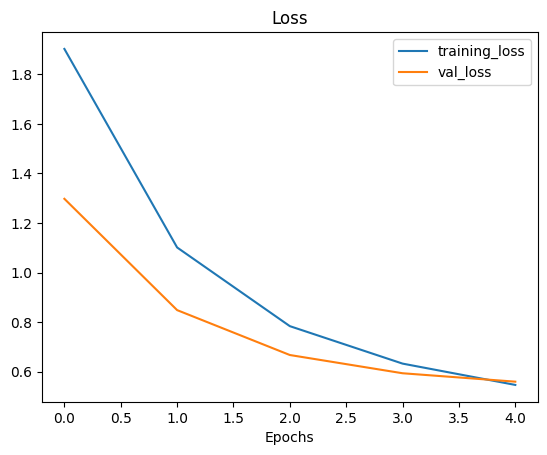

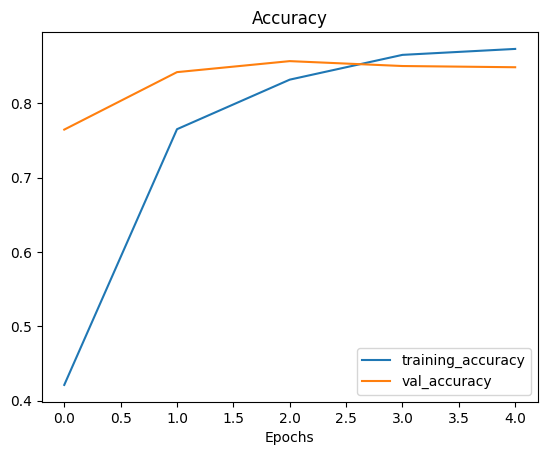

In [143]:
plot_loss_curves(history=history_0)

# Test the performance of Pooling layers

In [144]:
in_shape= (1,4,4,3)

tf.random.set_seed(42)
input_tensor = tf.random.normal(in_shape)
print(f"Random input tensor:\n {input_tensor}\n")

global_pooling = tf.keras.layers.GlobalAveragePooling2D()(input_tensor)
print(f"2D Global average pooled random tensor:\n {global_pooling}")

# tf.reduce_mean(), give the same results as tf.keras.layers.GlobalAveragePooling2D()
reduced = tf.reduce_mean(input_tensor, axis=[1,2])
print(f"2D reduced mean random tensor:\n {reduced}")

max_pooling = tf.keras.layers.GlobalMaxPooling2D()(input_tensor)
print(f"2D Global max pooled random tensor:\n {max_pooling}")

# tf.reduce_max(), give the same results as tf.keras.layers.GlobalMaxPooling2D()
reduced = tf.reduce_max(input_tensor, axis=[1,2])
print(f"2D reduced max random tensor:\n {reduced}")

print(f"Shape of input tensor: {input_tensor.shape}\n")
print(f"Shape of average pooled tensor: {global_pooling.shape}\n")
print(f"Shape of average max tensor: {max_pooling.shape}\n")


Random input tensor:
 [[[[ 0.3274685  -0.8426258   0.3194337 ]
   [-1.4075519  -2.3880599  -1.0392479 ]
   [-0.5573232   0.539707    1.6994323 ]
   [ 0.28893656 -1.5066116  -0.2645474 ]]

  [[-0.59722406 -1.9171132  -0.62044144]
   [ 0.8504023  -0.40604794 -3.0258412 ]
   [ 0.9058464   0.29855987 -0.22561555]
   [-0.7616443  -1.8917141  -0.93847126]]

  [[ 0.77852213 -0.47338894  0.97772694]
   [ 0.24694404  0.20573746 -0.52562326]
   [ 0.32410017  0.02545409 -0.10638496]
   [-0.63694745  1.1603122   0.2507359 ]]

  [[-0.41728503  0.4012578  -1.4145443 ]
   [-0.5931857  -1.6617213   0.33567193]
   [ 0.10815628  0.23479679 -0.56668764]
   [-0.35819843  0.88698614  0.52744764]]]]

2D Global average pooled random tensor:
 [[-0.09368646 -0.45840448 -0.2885598 ]]
2D reduced mean random tensor:
 [[-0.09368646 -0.45840448 -0.2885598 ]]
2D Global max pooled random tensor:
 [[0.9058464 1.1603122 1.6994323]]
2D reduced max random tensor:
 [[0.9058464 1.1603122 1.6994323]]
Shape of input tensor: 

# Experiment 1
**Model 1: Building a transfer learning model using Functional API rather than Sequential API.**

Using Feature Extractor with only 1% of the training data, and data augmentation

In [145]:
# Download 1% of the training data
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_1_percent.zip

--2026-10-13 15:33:45--  https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_1_percent.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.137.207, 142.251.2.207, 142.250.141.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.137.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 133612354 (127M) [application/zip]
Saving to: ‘10_food_classes_1_percent.zip.2’

10_food_classes_1_p 100%[===================>] 127.42M   175MB/s    in 0.7s    

2026-10-13 15:33:46 (175 MB/s) - ‘10_food_classes_1_percent.zip.2’ saved [133612354/133612354]



In [146]:
# Unzip the data - processed from Food101
unzip_data("/content/10_food_classes_1_percent.zip")

In [147]:
# Walk through the dataset
walk_through_dir("/content/10_food_classes_1_percent")

There are 2 directories and 0 images in '/content/10_food_classes_1_percent'.
There are 10 directories and 0 images in '/content/10_food_classes_1_percent/train'.
There are 0 directories and 7 images in '/content/10_food_classes_1_percent/train/sushi'.
There are 0 directories and 7 images in '/content/10_food_classes_1_percent/train/steak'.
There are 0 directories and 7 images in '/content/10_food_classes_1_percent/train/pizza'.
There are 0 directories and 7 images in '/content/10_food_classes_1_percent/train/hamburger'.
There are 0 directories and 7 images in '/content/10_food_classes_1_percent/train/chicken_curry'.
There are 0 directories and 7 images in '/content/10_food_classes_1_percent/train/ice_cream'.
There are 0 directories and 7 images in '/content/10_food_classes_1_percent/train/ramen'.
There are 0 directories and 7 images in '/content/10_food_classes_1_percent/train/grilled_salmon'.
There are 0 directories and 7 images in '/content/10_food_classes_1_percent/train/chicken_wi

In [148]:
# Create the training and test data dirs
train_dir_1_percent= "/content/10_food_classes_1_percent/train"
test_dir_1_percent= "/content/10_food_classes_1_percent/test"

In [149]:
# Set up data loaders
train_data_1_percent = image_dataset_from_directory(
    directory= train_dir_1_percent,
    label_mode="categorical",
    image_size= IMG_SIZE,
    batch_size=BATCH_SIZE,
)

test_data_1_percent = image_dataset_from_directory(
    directory=test_dir_1_percent,
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)


Found 70 files belonging to 10 classes.
Found 2500 files belonging to 10 classes.


# Data augmentation inside a model
**Benifits of using data augmentation inside the model:**


1.   Image preprocessing (augmentaion) happens on the GPU rather than the CPU.
2.   Image data augmentation happens during training, so we can export the whole model any where.



In [150]:
# Data augmantation using sequential API
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomHeight(0.2),
    layers.RandomWidth(0.2),
    # layers.Rescaling(1/255.0), # We do not use normalization layer as EfficientNet already has one.
    ], name="data_augmentation")

for i, layers.name in enumerate(data_augmentation.layers):
  print(i, layers.name)

0 <RandomFlip name=random_flip_20, built=False>
1 <RandomRotation name=random_rotation_20, built=False>
2 <RandomZoom name=random_zoom_20, built=False>
3 <RandomHeight name=random_height_20, built=False>
4 <RandomWidth name=random_width_20, built=False>


# Visualize our data augmentation layer

The selected random image path: /content/10_food_classes_1_percent/train/ramen/3362012.jpg
(448, 442, 3)


(np.float64(-0.5), np.float64(441.5), np.float64(447.5), np.float64(-0.5))

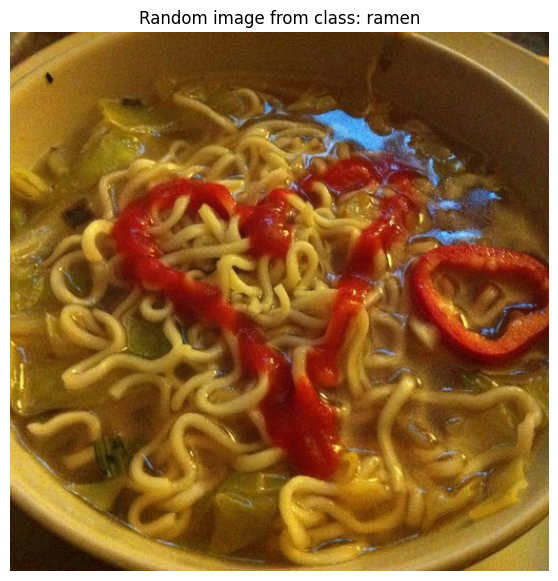

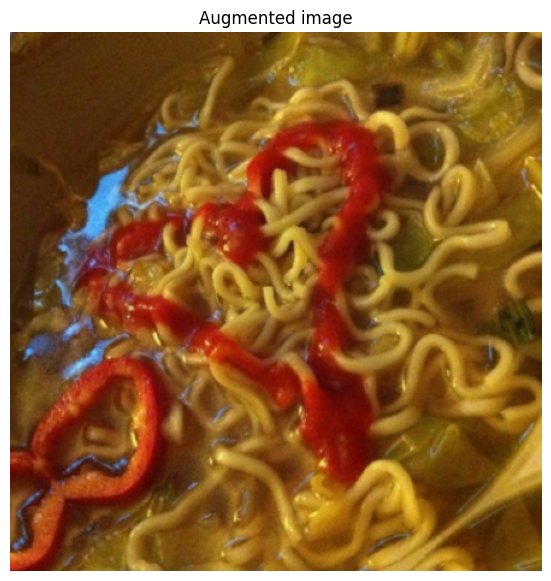

In [151]:
# Guess a random class in the dataset to read image from
target_class = random.choice(train_data_1_percent.class_names)
target_dir = train_dir_1_percent + "/" + target_class
# Selecting a random image within the random class or folder
random_image = random.choice(os.listdir(target_dir))
random_image_path = target_dir  + "/" + random_image
print(f"The selected random image path: {random_image_path}")

# Reading the random image
img = mpimg.imread(random_image_path)
plt.figure(figsize=(7,7))
plt.imshow(img)
plt.title(f"Random image from class: {target_class}")
plt.axis(False)

# Augmenting the image
augmented_img = data_augmentation(img)
print(augmented_img.shape)
plt.figure(figsize=(7,7))
plt.imshow(augmented_img/255.0)
plt.title("Augmented image")
plt.axis(False)

# Model 1
**Feature extraction transfer learning using 1% of the training data**

In [152]:
# Data augmantation using sequential API
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomHeight(0.2),
    layers.RandomWidth(0.2),
    ], name="data_augmentation")

In [153]:
# base-model is EfficientNetB0
base_model = keras.applications.EfficientNetB0(include_top=False)

#Freeze layers of the base_model
base_model.trainable = False

#Create the input layer
inputs = layers.Input(shape=INPUT_SHAPE, name="input_layer")

# Add the data augmentation layer
x = data_augmentation(inputs)

# Pass inputs to the base_model
x = base_model(x, training=False)

# Maxpooling the feature vector of the base model (dense the out put of the feature vector)
x = layers.GlobalAveragePooling2D(name="global_average_pooling") (x)

# Dense layer
outputs = layers.Dense(len(train_data_1_percent.class_names), activation="softmax", name="output_layer") (x)

# Make the model using the inputs and the outputs
model_1 = keras.Model(inputs, outputs)

# Compile the model
model_1.compile(
    loss="categorical_crossentropy",
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"]
)

In [154]:
# Fit model_1
history_1 = model_1.fit(
    train_data_1_percent,
    epochs=EPOCHS,
    steps_per_epoch=len(train_data_1_percent),
    validation_data= test_data_1_percent,
    validation_steps=len(test_data_1_percent),
    callbacks=[create_tensorboard_callback(
        dir_name="transfer_learning",
        experiment_name="model_1"
    )],
    verbose=1
)

Saving TensorBoard log files to: transfer_learning/model_1/20261013-153350
Epoch 1/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 24s 7s/step - accuracy: 0.1143 - loss: 2.4197 - val_accuracy: 0.1492 - val_loss: 2.2583
Epoch 2/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 3s/step - accuracy: 0.2143 - loss: 2.1606 - val_accuracy: 0.2296 - val_loss: 2.1332
Epoch 3/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 13s 5s/step - accuracy: 0.3429 - loss: 2.0135 - val_accuracy: 0.3084 - val_loss: 2.0180
Epoch 4/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 5s/step - accuracy: 0.5143 - loss: 1.8013 - val_accuracy: 0.3804 - val_loss: 1.9143
Epoch 5/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 4s/step - accuracy: 0.6143 - loss: 1.6391 - val_accuracy: 0.4432 - val_loss: 1.8214


In [155]:
model_1.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, None, None,     │     4,049,571 │
│                                 │ 1280)                  │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,088,003 (15.59 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

 Optimizer params: 25,622 (100.09 KB)

In [158]:
model_1.evaluate(test_data_1_percent)

79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.4432 - loss: 1.8214


[1.8214070796966553, 0.4431999921798706]

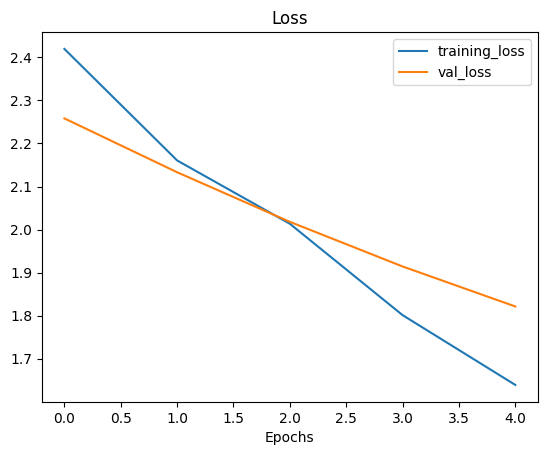

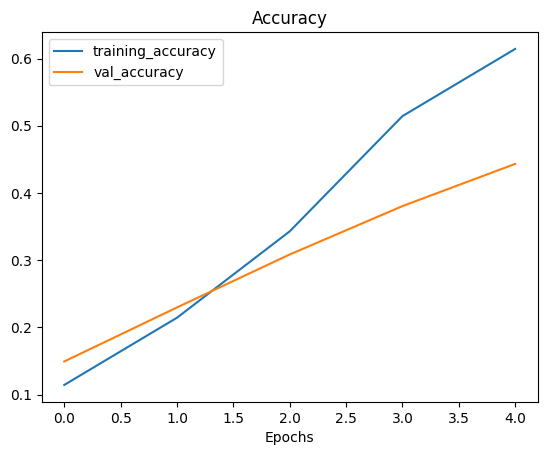

In [159]:
plot_loss_curves(history_1)